# 10장. 분류 분석으로 주문 취소 여부 예측하기

이 노트북은 완료 주문과 취소 주문만 사용해 `is_cancelled`를 예측하는 이진 분류 실습입니다.

## 학습 목표

- `completed=0`, `cancelled=1`로 타깃 범위를 명확하게 정의합니다.
- `refunded`와 기타 상태를 이진 분류 대상에서 제외합니다.
- 병합의 키 관계, 행 수, 미매칭을 검증합니다.
- train, validation, test를 분리합니다.
- Dummy 기준 모델, Logistic Regression, Random Forest를 비교합니다.
- validation에서 모델과 임계값을 선택하고 test는 최종 평가에 한 번만 사용합니다.
- 예측 결과에서 고객명 등 불필요한 개인정보를 제외합니다.


## 1. 프로젝트 루트와 실행 환경 설정

전처리 파일이 없다면 프로젝트 루트에서 먼저 다음 명령을 실행합니다.

```bash
python scripts/prepare_ch10_data.py
```


In [1]:
from pathlib import Path
import sys

import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / 'requirements.txt').exists() and (candidate / 'scripts').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트 폴더를 찾을 수 없습니다.')


PROJECT_ROOT = find_project_root(Path.cwd())
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('Python 실행 파일:', sys.executable)
print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('보고서 폴더:', REPORT_DIR)


import subprocess
prepare_result = subprocess.run(
    [sys.executable, str(PROJECT_ROOT / 'scripts' / 'prepare_ch10_data.py')],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=True,
)
input_reload_validation = pd.read_csv(REPORT_DIR / 'ch10_input_reload_validation.csv')
assert input_reload_validation['status'].eq('PASS').all()
print('공통 Raw부터 분류 입력 재생성·재로딩 검증: PASS')

Python 실행 파일: /home/gem/research/프로그램 모음/venvs/llm-data-analysis/bin/python
프로젝트 루트: /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study
전처리 데이터 폴더: /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/data/processed
보고서 폴더: /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports


공통 Raw부터 분류 입력 재생성·재로딩 검증: PASS


## 2. 전처리 데이터 확인과 불러오기

이 장에서는 `customers_clean.csv`, `orders_clean.csv`, `order_items_clean.csv`를 사용합니다.


In [2]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        '전처리 파일이 없습니다: '
        + ', '.join(str(path) for path in missing_files)
        + '. 먼저 python scripts/prepare_ch10_data.py를 실행하세요.'
    )

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

print('customers:', customers.shape, customers.columns.tolist())
print('orders:', orders.shape, orders.columns.tolist())
print('order_items:', order_items.shape, order_items.columns.tolist())


customers: (150, 6) ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
orders: (300, 7) ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status', 'order_month', 'order_dayofweek']
order_items: (764, 6) ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'line_total']


## 3. 주문 상태와 타깃 범위 확인

이번 실습은 완료 주문과 취소 주문만 비교합니다.

- `completed` → 0
- `cancelled` → 1
- `refunded`와 기타 상태 → 학습 대상에서 제외


In [3]:
status_summary = (
    orders['order_status']
    .value_counts(dropna=False)
    .rename_axis('order_status')
    .reset_index(name='order_count')
)
status_summary


,order_status,order_count
0,completed,184
1,cancelled,64
2,refunded,52


## 4. 분류 데이터와 병합 검증표 생성

공통 함수는 주문 특징 집계, 안전한 병합, 시간 순서 점검, 타깃 생성까지 수행합니다.


In [4]:
from src.classification import (
    build_classification_dataset,
    target_distribution,
)

(
    model_data,
    numeric_features,
    categorical_features,
    merge_checks,
    data_quality_checks,
) = build_classification_dataset(
    customers=customers,
    orders=orders,
    order_items=order_items,
)

target_dist = target_distribution(model_data)

print('모델링 데이터:', model_data.shape)
print('숫자형 feature:', numeric_features)
print('범주형 feature:', categorical_features)
display(target_dist)
display(merge_checks)
display(data_quality_checks)


모델링 데이터: (248, 16)
숫자형 feature: ['age', 'item_count', 'total_quantity', 'order_amount', 'order_month', 'order_dayofweek', 'days_since_signup']
범주형 feature: ['gender', 'city', 'payment_method']


,is_cancelled,class_label,count,ratio
0,0,completed,184,0.7419
1,1,cancelled,64,0.2581


,merge,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → order_item_features,248,248,True,0,PASS
1,customer_id → customers,248,248,True,0,PASS


,check_item,count
0,binary_target_rows,248
1,completed_rows,184
2,cancelled_rows,64
3,excluded_status_rows,52
4,line_total_mismatch,0
5,negative_days_since_signup,45
6,missing_order_item_features,0
7,missing_customer_match,0
8,status_scope:completed,184
9,status_scope:cancelled,64


## 5. 데이터 누수 확인

`order_status`와 `is_cancelled`는 입력 feature에 포함되면 안 됩니다.


In [5]:
features = numeric_features + categorical_features
leakage_columns = {'order_status', 'is_cancelled'}
leakage_found = sorted(leakage_columns.intersection(features))

if leakage_found:
    raise ValueError(f'데이터 누수 위험 컬럼이 포함되었습니다: {leakage_found}')

print('사용 feature:', features)
print('데이터 누수 컬럼 없음')


사용 feature: ['age', 'item_count', 'total_quantity', 'order_amount', 'order_month', 'order_dayofweek', 'days_since_signup', 'gender', 'city', 'payment_method']
데이터 누수 컬럼 없음


## 6. train, validation, test 분리

모델과 임계값은 validation에서 선택하고, test는 최종 평가에 한 번만 사용합니다.


In [6]:
from src.classification import (
    split_train_validation_test,
    build_split_summary,
)

(
    X_train,
    X_valid,
    X_test,
    y_train,
    y_valid,
    y_test,
    features,
) = split_train_validation_test(
    model_data=model_data,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    random_state=42,
)

split_summary = build_split_summary(y_train, y_valid, y_test)

print('X_train:', X_train.shape)
print('X_valid:', X_valid.shape)
print('X_test:', X_test.shape)
display(split_summary)


X_train: (148, 10)
X_valid: (50, 10)
X_test: (50, 10)


,split,is_cancelled,class_label,count,ratio
0,train,0,completed,110,0.7432
1,train,1,cancelled,38,0.2568
2,validation,0,completed,37,0.7400
3,validation,1,cancelled,13,0.2600
4,test,0,completed,37,0.7400
5,test,1,cancelled,13,0.2600


## 7. 기준 모델과 학습 모델 비교

가장 많은 클래스만 예측하는 Dummy 모델을 기준으로 Logistic Regression과 Random Forest의 validation 성능을 비교합니다.


In [7]:
from src.classification import train_and_compare_on_validation

(
    models,
    validation_comparison,
    validation_predictions,
    validation_probabilities,
) = train_and_compare_on_validation(
    X_train=X_train,
    X_valid=X_valid,
    y_train=y_train,
    y_valid=y_valid,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    random_state=42,
)

validation_comparison


,model,evaluation_split,accuracy,precision,recall,f1
0,Logistic Regression,validation,0.66,0.388889,0.538462,0.451613
1,Random Forest,validation,0.66,0.300000,0.230769,0.260870
2,Dummy Most Frequent,validation,0.74,0.000000,0.000000,0.000000


## 8. validation에서 모델과 임계값 선택

Dummy 모델은 기준선이므로 실제 선택 후보에서는 제외합니다. validation의 f1-score를 우선하고 recall과 precision을 함께 확인합니다.


In [8]:
from src.classification import (
    threshold_metrics,
    choose_threshold,
    select_validation_model,
)

selected_model_name = select_validation_model(validation_comparison)
selected_model = models[selected_model_name]
validation_proba = validation_probabilities[selected_model_name]

threshold_df = threshold_metrics(y_valid, validation_proba)
selected_threshold = choose_threshold(threshold_df)

print('Validation에서 선택한 모델:', selected_model_name)
print('Validation에서 선택한 임계값:', selected_threshold)
display(threshold_df.sort_values(['f1', 'recall'], ascending=False).head(10))


Validation에서 선택한 모델: Logistic Regression
Validation에서 선택한 임계값: 0.2


,threshold,accuracy,precision,recall,f1
0,0.20,0.38,0.295455,1.000000,0.456140
9,0.65,0.76,0.555556,0.384615,0.454545
6,0.50,0.66,0.388889,0.538462,0.451613
1,0.25,0.40,0.292683,0.923077,0.444444
4,0.40,0.58,0.333333,0.615385,0.432432
7,0.55,0.68,0.400000,0.461538,0.428571
3,0.35,0.50,0.300000,0.692308,0.418605
2,0.30,0.44,0.285714,0.769231,0.416667
5,0.45,0.60,0.333333,0.538462,0.411765
8,0.60,0.70,0.416667,0.384615,0.400000


## 9. test 데이터 최종 평가

이제 선택이 끝났으므로 test 데이터에서 최종 성능을 한 번 확인합니다.


In [9]:
from src.classification import (
    final_test_evaluation,
    confusion_matrix_dataframe,
    classification_report_dataframe,
)

y_pred_test, y_proba_test, test_metrics = final_test_evaluation(
    selected_model,
    X_test,
    y_test,
    threshold=selected_threshold,
    model_name=selected_model_name,
)

confusion_df = confusion_matrix_dataframe(y_test, y_pred_test)
classification_report_df = classification_report_dataframe(y_test, y_pred_test)

display(test_metrics)
display(confusion_df)
display(classification_report_df)


,model,evaluation_split,threshold,selection_status,accuracy,precision,recall,f1
0,Logistic Regression,test_final,0.2,frozen_before_test,0.28,0.244444,0.846154,0.37931


,pred_completed,pred_cancelled
actual_completed,3,34
actual_cancelled,2,11


,label,precision,recall,f1-score,support
0,completed,0.600000,0.081081,0.142857,37.00
1,cancelled,0.244444,0.846154,0.379310,13.00
2,accuracy,0.280000,0.280000,0.280000,0.28
3,macro avg,0.422222,0.463617,0.261084,50.00
4,weighted avg,0.507556,0.280000,0.204335,50.00


혼동행렬은 다음처럼 읽습니다.

| 구분 | 의미 |
|---|---|
| True Negative | 실제 완료 주문을 완료로 예측 |
| False Positive | 실제 완료 주문을 취소로 잘못 예측 |
| False Negative | 실제 취소 주문을 완료로 잘못 예측 |
| True Positive | 실제 취소 주문을 취소로 예측 |


## 10. Internal 결과와 Public 결과를 분리합니다

오류 추적용 `source_index`는 내부 결과에만 유지하고, Notebook과 GitHub에는 식별자를 제거한 공개 결과만 표시합니다.


In [10]:
from src.classification import create_prediction_result, public_prediction_result

prediction_result_internal = create_prediction_result(
    source_index=X_test.index,
    y_test=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=selected_model_name,
    threshold=selected_threshold,
)
prediction_result_public = public_prediction_result(prediction_result_internal)
print('공개 컬럼:', prediction_result_public.columns.tolist())
prediction_result_public.head()


공개 컬럼: ['record_id', 'actual_is_cancelled', 'predicted_is_cancelled', 'cancel_probability', 'model', 'threshold']


,record_id,actual_is_cancelled,predicted_is_cancelled,cancel_probability,model,threshold
0,test_0001,0,1,0.576120,Logistic Regression,0.2
1,test_0002,0,1,0.462559,Logistic Regression,0.2
2,test_0003,0,1,0.406685,Logistic Regression,0.2
3,test_0004,0,1,0.829364,Logistic Regression,0.2
4,test_0005,0,1,0.883050,Logistic Regression,0.2


## 11. LLM 코드 검토 체크리스트


In [11]:
from src.classification import build_classification_checklist

classification_checklist = build_classification_checklist()
classification_checklist


,check_item,status
0,completed와 cancelled만 사용해 이진 타깃을 만들었는가?,□
1,refunded 등 다른 상태를 0 클래스에 섞지 않았는가?,□
2,예측 시점과 feature 가용성 가정을 설명할 수 있는가?,□
3,line_total = quantity × unit_price를 검증했는가?,□
4,병합에 validate를 사용하고 미매칭 0건을 확인했는가?,□
5,"order_status, target, ID, 사후 정보를 feature에서 제외했는가?",□
6,"train, validation, test를 분리했는가?",□
7,모델과 threshold는 validation에서 선택했는가?,□
8,모델과 threshold를 고정한 뒤 test를 한 번만 사용했는가?,□
9,Dummy 기준 모델과 비교했는가?,□


## 12. 전체 파이프라인 실행과 산출물 저장

위 과정을 한 번에 다시 실행해 CSV와 Markdown 보고서를 생성합니다.


In [12]:
from src.classification import run_classification_analysis

classification_result = run_classification_analysis(
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    random_state=42,
)

print('선택 모델:', classification_result['selected_model_name'])
print('선택 임계값:', classification_result['selected_threshold'])
display(classification_result['test_metrics'])

for name, path in classification_result['output_paths'].items():
    print(name, path, 'OK' if path.exists() else 'MISSING')


선택 모델: Logistic Regression
선택 임계값: 0.2


,model,evaluation_split,threshold,selection_status,accuracy,precision,recall,f1
0,Logistic Regression,test_final,0.2,frozen_before_test,0.28,0.244444,0.846154,0.37931


model_data_internal /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch10_classification_model_data_internal.csv OK
target_distribution /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch10_target_distribution.csv OK
feature_audit /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch10_feature_audit.csv OK
merge_checks /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch10_merge_checks.csv OK
data_quality_checks /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch10_data_quality_checks.csv OK
split_summary /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch10_split_summary.csv OK
validation_comparison /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch10_validation_model_comparison.csv OK
threshold_metrics /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch10_validation_threshold_metrics.csv OK
test_metrics /home/gem/research/4. 학교 수업/LLM 수업/llm-da

## 13. LLM 검토 프롬프트 예시

```text
온라인 쇼핑몰 주문 취소 분류 코드를 검토해 주세요.

타깃 기준:
- completed=0
- cancelled=1
- refunded와 기타 상태는 제외

검토 항목:
1. order_status와 is_cancelled가 feature에서 제외되었는가?
2. 병합에 validate와 indicator가 사용되었는가?
3. train, validation, test가 분리되었는가?
4. 모델과 임계값은 validation에서 선택했는가?
5. test는 최종 평가에 한 번만 사용했는가?
6. Dummy 기준 모델보다 나은가?
7. accuracy, precision, recall, f1을 함께 확인했는가?
8. 예측 결과에 개인정보가 포함되지 않았는가?
9. 모델 결과를 취소 원인으로 단정하지 않았는가?

필수 수정과 권장 개선을 구분해 설명해 주세요.
```


## 14. 정리

이번 장에서는 완료 주문과 취소 주문을 명확하게 구분하고, 병합 검증, 데이터 누수 방지, train/validation/test 분리, 기준 모델 비교, validation 기반 모델·임계값 선택, 최종 test 평가를 수행했습니다.

다음 장에서는 LLM을 활용해 분석 질문과 프롬프트를 더 구체적으로 만드는 방법으로 이어집니다.


# Chapter 10 제출 답안

- **GitHub ID:** `chocoemong1`
- **작성일:** 2026-11-10
- **최종 Notebook URL:** <https://github.com/chocoemong1/llm-data-analysis-study/blob/main/chapter10/chapter10.ipynb>

아래 답안은 위 코드와 저장된 Validation Evidence를 직접 확인해 작성했습니다.


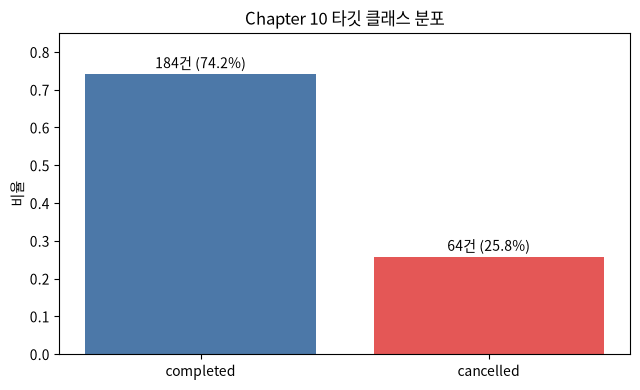

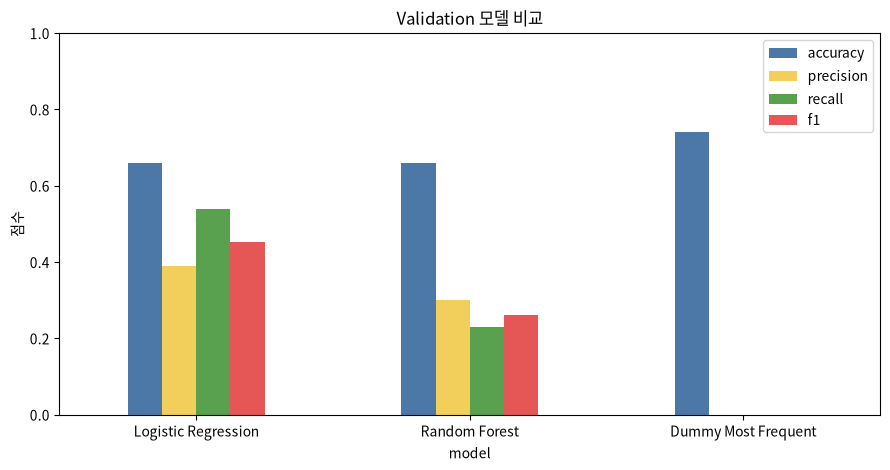

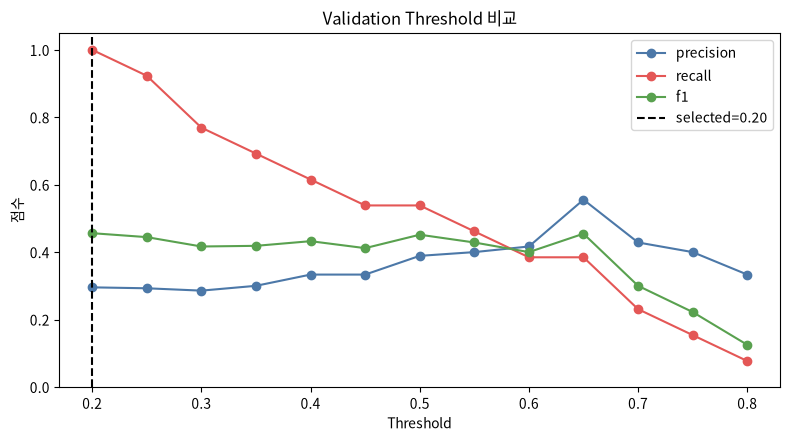

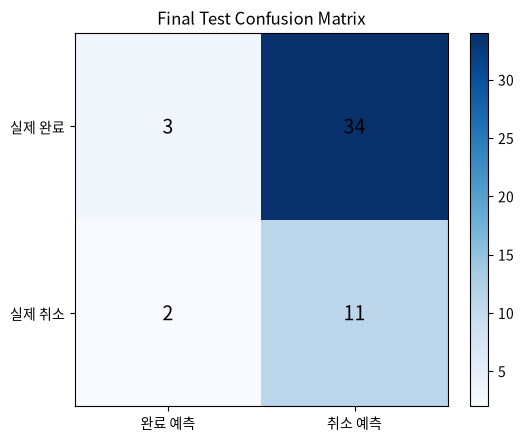

Evidence: ['step02_class_ratio.png', 'step03_baseline.png', 'step05_threshold.png', 'step06_confusion_matrix.png']


In [13]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np

IMAGE_DIR = PROJECT_ROOT / "chapter10" / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

font_candidates = [
    Path.home() / "research" / "프로그램 모음" / "tools" / "fonts" / "noto-cjk-20230817" / "NotoSansCJKkr-Regular.otf",
    Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"),
]
font_path = next((p for p in font_candidates if p.exists()), None)
if font_path:
    font_manager.fontManager.addfont(font_path)
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

# 1) 클래스 비율
fig, ax = plt.subplots(figsize=(6.5, 4))
labels = target_dist["class_label"].tolist()
bars = ax.bar(labels, target_dist["ratio"], color=["#4C78A8", "#E45756"])
for bar, count, ratio in zip(bars, target_dist["count"], target_dist["ratio"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.015, f"{count}건 ({ratio:.1%})", ha="center")
ax.set_ylim(0, 0.85); ax.set_ylabel("비율"); ax.set_title("Chapter 10 타깃 클래스 분포")
fig.tight_layout(); fig.savefig(IMAGE_DIR / "step02_class_ratio.png", dpi=160, bbox_inches="tight")
plt.show()

# 2) Validation 모델 비교
metric_cols = ["accuracy", "precision", "recall", "f1"]
plot_df = validation_comparison.set_index("model")[metric_cols]
ax = plot_df.plot(kind="bar", figsize=(9, 4.8), ylim=(0, 1), rot=0, color=["#4C78A8", "#F2CF5B", "#59A14F", "#E45756"])
ax.set_title("Validation 모델 비교"); ax.set_ylabel("점수"); ax.legend(loc="upper right")
ax.figure.tight_layout(); ax.figure.savefig(IMAGE_DIR / "step03_baseline.png", dpi=160, bbox_inches="tight")
plt.show()

# 3) Validation threshold 비교
fig, ax = plt.subplots(figsize=(8, 4.5))
for metric, color in [("precision", "#4C78A8"), ("recall", "#E45756"), ("f1", "#59A14F")]:
    ax.plot(threshold_df["threshold"], threshold_df[metric], marker="o", label=metric, color=color)
ax.axvline(selected_threshold, color="black", linestyle="--", label=f"selected={selected_threshold:.2f}")
ax.set_ylim(0, 1.05); ax.set_xlabel("Threshold"); ax.set_ylabel("점수"); ax.set_title("Validation Threshold 비교"); ax.legend()
fig.tight_layout(); fig.savefig(IMAGE_DIR / "step05_threshold.png", dpi=160, bbox_inches="tight")
plt.show()

# 4) Final Test confusion matrix
matrix = confusion_df.to_numpy()
fig, ax = plt.subplots(figsize=(5.3, 4.5))
im = ax.imshow(matrix, cmap="Blues")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j, i, str(matrix[i, j]), ha="center", va="center", fontsize=14)
ax.set_xticks([0,1], ["완료 예측", "취소 예측"]); ax.set_yticks([0,1], ["실제 완료", "실제 취소"])
ax.set_title("Final Test Confusion Matrix"); fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); fig.savefig(IMAGE_DIR / "step06_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

print("Evidence:", sorted(p.name for p in IMAGE_DIR.glob("*.png")))


## 1. 분류 문제·Feature Contract

- **타깃:** 주문 취소 여부(`completed=0`, `cancelled=1`), `refunded` 52건은 제외
- **예측 단위/시점:** 주문 1건, 주문 생성 직후
- **숫자형:** `age`, `item_count`, `total_quantity`, `order_amount`, 주문 월·요일, 가입 후 경과일
- **범주형:** `gender`, `city`, `payment_method`
- **금지:** `order_status`, `is_cancelled`, 각종 ID, 취소 사유·시각 등 사후 정보

### 나의 해석과 판단
파일에 존재해도 예측 시점 이후 정보나 Target·식별자는 사용할 수 없습니다. 주문 생성 직후 알 수 있는 정보만 사용해야 누수 없는 성능입니다.

### 한계
`order_amount` 등 주문 상세 집계는 주문 생성 시 장바구니가 확정돼 있다는 교육용 가정입니다. 운영 시 실제 입력 가능 시점을 다시 확인해야 합니다.


## 2. 주문 특징·품질·병합 검증

- `line_total = quantity × unit_price` 불일치: **0건**
- 주문 특징의 `order_id` 중복: **0건**
- 주문↔주문 특징 `one_to_one`: **248→248, 미매칭 0, PASS**
- 주문↔고객 `many_to_one`: **248→248, 미매칭 0, PASS**
- 원본에는 가입일이 주문일보다 늦은 이진 대상 주문이 **45건** 있었습니다. 원본 날짜를 임의 수정하거나 행을 삭제하지 않고 해당 `days_since_signup`만 결측 처리했으며, Train Pipeline의 중앙값으로 대체했습니다.

### 나의 해석과 판단
미매칭을 0으로 채우면 실제 0과 데이터 연결 실패를 구분할 수 없습니다. 이번 병합은 모두 일치했지만 날짜 불일치는 별도 품질 Evidence로 남겨 모델 한계에 반영했습니다.


## 3. 클래스 비율과 Validation 모델 선택

![클래스 비율](images/step02_class_ratio.png)

- completed: **184건(74.19%)**
- cancelled: **64건(25.81%)**

Dummy는 Accuracy가 0.74이지만 취소 Precision·Recall·F1이 모두 0입니다. 따라서 Accuracy만 보면 취소를 하나도 찾지 못하는 모델을 좋은 모델로 오해할 수 있습니다.

![Validation 모델 비교](images/step03_baseline.png)

| 모델 | Accuracy | Precision | Recall | F1 |
| --- | ---: | ---: | ---: | ---: |
| Dummy Most Frequent | 0.740 | 0.000 | 0.000 | 0.000 |
| Logistic Regression | 0.660 | 0.389 | 0.538 | 0.452 |
| Random Forest | 0.660 | 0.300 | 0.231 | 0.261 |

**Validation에서 Logistic Regression을 고정**했습니다. Dummy보다 Accuracy는 낮지만 취소 탐지 Recall·F1이 실질적으로 개선됐기 때문입니다.


## 4. Split·Threshold 선택

- Train: 148건(완료 110, 취소 38) — 학습
- Validation: 50건(완료 37, 취소 13) — 모델·Threshold 선택
- Final Test: 50건(완료 37, 취소 13) — 선택 고정 후 최종 평가

![Threshold 비교](images/step05_threshold.png)

Validation에서 F1을 우선하고 Recall·Precision을 함께 비교해 **Threshold 0.20**을 선택했습니다. 이때 Precision 0.295, Recall 1.000, F1 0.456이었습니다. 취소 누락(FN)을 줄이는 쪽을 우선한 선택이지만 FP 증가를 감수합니다.

### 한계
Stratified random split은 교육용입니다. 운영 전에는 시간 순서의 out-of-time 평가와 기간별 성능 안정성 검증이 필요합니다. Final Test를 보고 모델이나 Threshold를 다시 바꾸지 않았습니다.


## 5. Final Test·FP/FN 해석

![Confusion Matrix](images/step06_confusion_matrix.png)

- **Accuracy 0.280, Precision 0.244, Recall 0.846, F1 0.379**
- TN 3, FP 34, FN 2, TP 11

### 결과 관찰
Validation보다 Final Test의 F1과 Recall이 낮아졌고, 완료 주문 37건 중 34건을 취소 위험으로 잘못 분류했습니다.

### 나의 해석과 판단
FN 2건으로 취소 누락은 적지만 FP 34건이 너무 많아 경보 피로와 불필요한 고객 확인 비용이 큽니다. 실제 FP/FN 비용 정보가 없으므로 어느 오류가 더 비싼지는 확정할 수 없습니다.

### 업무·분석적 의미와 한계
취소 위험 선별의 참고 신호로도 즉시 사용하기 어렵습니다. 취소 시점·사유, 재고·배송·결제 실패 정보와 시간순 검증이 추가로 필요하며, 현재 패턴을 취소 원인으로 해석할 수 없습니다.


## 6. Privacy·Validation·LLM 검토

- 공개 Prediction: `record_id`, 실제/예측 타깃, 확률, 모델, threshold만 포함
- `source_index`, `order_id`, `customer_id`, `product_id`는 공개 결과에서 제외
- Validation의 Target, 누수, 병합, Split, 모델·Threshold 선택, Public Privacy, Final Test 고정 평가가 모두 **PASS**

### LLM 검토 기록
LLM은 공식 코드의 실행 경로, Feature Leakage, Validation/Test 보호, Privacy-safe Output을 검토하는 데 사용했습니다. 제안은 실제 원본 해시·실행 결과·Validation 표로 확인했습니다. 공식 데이터의 날짜 불일치는 삭제나 임의 수정 대신 파생값 결측 처리로 수정했고, 그 건수를 숨기지 않았습니다.

자동 PASS는 코드 계약을 확인할 뿐 운영 적합성·공정성·시간 변화 안정성을 보장하지 않습니다.


## 7. 최종 사용 판단

**현재 사용 보류**로 판단합니다.

1. Dummy보다 취소 Recall·F1은 개선됐지만 Final Test Precision이 0.244이고 FP가 34건입니다.
2. Validation F1 0.456에서 Test F1 0.379로 낮아져 일반화 성능이 충분하지 않습니다.
3. Random split, 248건의 작은 표본, 가입일 품질 문제 때문에 운영 성능을 확신할 수 없습니다.

**개선 우선순위:** 날짜 품질 정정 → 더 긴 기간·취소 관련 선행 정보 확보 → 시간순 Validation/Test → 실제 FP/FN 비용을 반영한 Threshold 재선택.


In [14]:
from src.classification import build_feature_audit

feature_audit = build_feature_audit(numeric_features, categorical_features)
display(feature_audit)
display(merge_checks)
display(data_quality_checks)
display(classification_result["validation"])

public_forbidden = {"source_index", "order_id", "customer_id", "product_id", "name", "email", "phone", "address"}
assert not (public_forbidden & set(classification_result["prediction_result"].columns))
assert classification_result["validation"]["status"].eq("PASS").all()
print("PUBLIC PRIVACY + VALIDATION: PASS")


,column,selected,role,reason
0,age,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
1,item_count,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
2,total_quantity,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
3,order_amount,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
4,order_month,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
5,order_dayofweek,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
6,days_since_signup,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
7,gender,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
8,city,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
9,payment_method,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정


,merge,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → order_item_features,248,248,True,0,PASS
1,customer_id → customers,248,248,True,0,PASS


,check_item,count
0,binary_target_rows,248
1,completed_rows,184
2,cancelled_rows,64
3,excluded_status_rows,52
4,line_total_mismatch,0
5,negative_days_since_signup,45
6,missing_order_item_features,0
7,missing_customer_match,0
8,status_scope:completed,184
9,status_scope:cancelled,64


,check,value,status
0,binary_target_contract,"[0, 1]",PASS
1,forbidden_feature_overlap,0,PASS
2,strict_merge_contract,True,PASS
3,all_splits_have_both_classes,True,PASS
4,selected_model_from_validation,True,PASS
5,selected_threshold_from_validation,True,PASS
6,public_prediction_privacy,none,PASS
7,test_rows_for_metrics,50,PASS
8,final_test_frozen_evaluation,True,PASS


PUBLIC PRIVACY + VALIDATION: PASS


## 8. 전체 재실행과 제출 체크

아래 셀은 블로그가 지정한 두 스크립트를 새 프로세스로 실행하고, 결과 파일·이미지·Validation을 마지막으로 확인합니다.


In [15]:
import subprocess

script_results = []
for script_name in ["prepare_ch10_data.py", "run_classification_analysis.py"]:
    completed = subprocess.run(
        [sys.executable, str(PROJECT_ROOT / "scripts" / script_name)],
        cwd=PROJECT_ROOT,
        text=True,
        capture_output=True,
        check=False,
    )
    script_results.append({
        "script": script_name,
        "returncode": completed.returncode,
        "status": "PASS" if completed.returncode == 0 else "FAIL",
    })
    if completed.returncode != 0:
        print(completed.stdout)
        print(completed.stderr)

script_validation = pd.DataFrame(script_results)
display(script_validation)
assert script_validation["status"].eq("PASS").all()

validation_file = pd.read_csv(REPORT_DIR / "ch10_classification_validation.csv")
public_predictions = pd.read_csv(REPORT_DIR / "ch10_classification_predictions.csv")
input_reload = pd.read_csv(REPORT_DIR / 'ch10_input_reload_validation.csv')
output_reload = pd.read_csv(REPORT_DIR / 'ch10_output_reload_validation.csv')
artifact_files = pd.read_csv(REPORT_DIR / 'ch10_file_validation.csv')
required_files = [
    IMAGE_DIR / "step02_class_ratio.png",
    IMAGE_DIR / "step03_baseline.png",
    IMAGE_DIR / "step05_threshold.png",
    IMAGE_DIR / "step06_confusion_matrix.png",
    REPORT_DIR / "ch10_classification_validation.csv",
    REPORT_DIR / "ch10_classification_predictions.csv",
    REPORT_DIR / "ch10_input_reload_validation.csv",
    REPORT_DIR / "ch10_output_reload_validation.csv",
    REPORT_DIR / "ch10_file_validation.csv",
]
file_checks = pd.DataFrame([
    {"file": p.relative_to(PROJECT_ROOT).as_posix(), "exists": p.exists(), "nonempty": p.exists() and p.stat().st_size > 0}
    for p in required_files
])
display(validation_file)
display(file_checks)
display(input_reload)
display(output_reload)
display(artifact_files)
assert validation_file["status"].eq("PASS").all()
assert input_reload['status'].eq('PASS').all()
assert output_reload['status'].eq('PASS').all()
assert artifact_files['status'].eq('PASS').all()
assert not (public_forbidden & set(public_predictions.columns))
assert file_checks[["exists", "nonempty"]].all().all()
print("FINAL SUBMISSION GATE: PASS")


,script,returncode,status
0,prepare_ch10_data.py,0,PASS
1,run_classification_analysis.py,0,PASS


,check,value,status
0,binary_target_contract,"[0, 1]",PASS
1,forbidden_feature_overlap,0,PASS
2,strict_merge_contract,True,PASS
3,all_splits_have_both_classes,True,PASS
4,selected_model_from_validation,True,PASS
5,selected_threshold_from_validation,True,PASS
6,public_prediction_privacy,none,PASS
7,test_rows_for_metrics,50,PASS
8,final_test_frozen_evaluation,True,PASS


,file,exists,nonempty
0,chapter10/images/step02_class_ratio.png,True,True
1,chapter10/images/step03_baseline.png,True,True
2,chapter10/images/step05_threshold.png,True,True
3,chapter10/images/step06_confusion_matrix.png,True,True
4,reports/ch10_classification_validation.csv,True,True
5,reports/ch10_classification_predictions.csv,True,True
6,reports/ch10_input_reload_validation.csv,True,True
7,reports/ch10_output_reload_validation.csv,True,True
8,reports/ch10_file_validation.csv,True,True


,check,value,status
0,customers.shape,"(150, 6)",PASS
1,customers.columns,6,PASS
2,customers.customer_id_unique_nonnull,0,PASS
3,products.shape,"(100, 4)",PASS
4,products.columns,4,PASS
5,products.product_id_unique_nonnull,0,PASS
6,orders.shape,"(300, 7)",PASS
7,orders.columns,7,PASS
8,orders.order_id_unique_nonnull,0,PASS
9,order_items.shape,"(764, 6)",PASS


,artifact,value,exists,shape_match,columns_match,content_match,status
0,model_data_internal,"shape=(248, 13)",True,True,True,True,PASS
1,target_distribution,"shape=(2, 4)",True,True,True,True,PASS
2,feature_audit,"shape=(17, 4)",True,True,True,True,PASS
3,merge_checks,"shape=(2, 6)",True,True,True,True,PASS
4,data_quality_checks,"shape=(11, 2)",True,True,True,True,PASS
5,split_summary,"shape=(6, 5)",True,True,True,True,PASS
6,validation_comparison,"shape=(3, 6)",True,True,True,True,PASS
7,threshold_metrics,"shape=(13, 5)",True,True,True,True,PASS
8,test_metrics,"shape=(1, 8)",True,True,True,True,PASS
9,predictions_internal,"shape=(50, 7)",True,True,True,True,PASS


,artifact,value,exists,status
0,ch10_classification_summary.md,bytes=6914,True,PASS


FINAL SUBMISSION GATE: PASS


### 최종 체크

- [x] `completed=0`, `cancelled=1`; 기타 상태 제외
- [x] 예측 시점·허용/금지 Feature 정의
- [x] 계산·병합·클래스 비율·Dummy 비교
- [x] Pipeline을 Train에서만 학습
- [x] 모델과 Threshold를 Validation에서 고정
- [x] Final Test에서 Precision·Recall·F1·FP/FN 확인
- [x] 공개 결과 식별자 제거 및 Validation PASS
- [x] random split·데이터 품질·인과 해석 한계 기록
- [x] 두 스크립트와 Notebook 전체 재실행

- [x] 입력·결과 CSV 재로딩과 보고서 파일 검증 PASS